Chapters 7 to 13 built forecasts from statistical models: regressions, exponential smoothing and ARIMA, each with an explicit equation whose parameters we estimate and test. This chapter takes a machine-learning route. A **gradient-boosted tree ensemble** learns the forecast function from the data, as a sum of many small decision trees, without a model equation written down in advance. **XGBoost** (eXtreme Gradient Boosting) is the best-known implementation, and it has won a large share of forecasting competitions on tabular data.

A tree ensemble does not know that the data are ordered in time. To use it for forecasting, we turn the time series into a table: each row is a time stamp, the target is the value of the series, and the predictors (**features**) are things we know about that time stamp in advance, such as the hour, the day of the week and the month. In this chapter, we forecast the hourly electricity load of the PJM East region with such calendar features.

# Learning objectives

By the end of this lecture you should be able to

1. explain how a regression tree partitions the predictor space, and how gradient boosting builds a forecast as a sum of small trees, each fitted to the residuals of the previous ones;
2. write down the regularized objective of XGBoost and say what the learning rate, the tree depth, the number of trees and the penalty $\lambda$ control;
3. turn a time series into a table of calendar features, and split it into training, validation and test periods in time order;
4. choose the number of trees by early stopping on a validation period, without touching the test period;
5. read feature importances, evaluate the forecasts with the RMSE, MAE and MAPE against a simple benchmark, and explain why a tree ensemble cannot extrapolate a trend;
6. find where the model fails by looking at the worst-predicted days, and design a holiday feature to address part of it.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `sqrt`, `abs`, `mean`, `arange` |
| `pandas` | `read_csv`, `groupby`, `resample`, `date_range`, `isocalendar` |
| `pandas.tseries.holiday` | `USFederalHolidayCalendar` -- the dates of the US federal holidays |
| `matplotlib.pyplot` | `subplots`, `plot`, `boxplot`, `barh` |
| `time` | `perf_counter` -- timing the fits |
| `xgboost` | `XGBRegressor` -- the gradient-boosted tree ensemble |

XGBoost is not part of the standard scientific Python stack. Install it once with `pip install xgboost` in the environment that runs these notebooks.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar

import xgboost as xgb

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4), the MSE (Chapter 6) and the MAPE (Chapter 12).

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)


def mape(observations, estimates):
    "Mean absolute percentage error, in percent."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    return 100 * np.mean(np.abs((observations - estimates) / observations))

New in this chapter: the mean absolute error, a function that collects the three accuracy measures in one row, and `create_features`, which turns a time index into a table of calendar features.

In [3]:
def mae(observations, estimates):
    "Mean absolute error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    return np.mean(np.abs(observations - estimates))


def accuracy(observations, estimates):
    "RMSE, MAE and MAPE of a forecast, as a dict (one row of a comparison table)."
    return {"RMSE": np.sqrt(mse(observations, estimates)), "MAE": mae(observations, estimates),
            "MAPE (%)": mape(observations, estimates)}


def create_features(index, holidays=None):
    "Calendar features of a DatetimeIndex; with a list of holiday dates, also a 0/1 holiday column."
    X = pd.DataFrame(index=index)
    X["hour"] = index.hour
    X["dayofweek"] = index.dayofweek          # Monday = 0, ..., Sunday = 6
    X["quarter"] = index.quarter
    X["month"] = index.month
    X["year"] = index.year
    X["dayofyear"] = index.dayofyear
    X["dayofmonth"] = index.day
    X["weekofyear"] = index.isocalendar().week.to_numpy().astype(int)
    if holidays is not None:
        X["holiday"] = index.normalize().isin(holidays).astype(int)
    return X

---

# From regression trees to gradient boosting

## Regression trees

A **regression tree** splits the predictor space into rectangular regions $R_1, \dots, R_T$ by a sequence of yes/no questions such as "is the hour < 7?" and "is the month < 5?", and predicts a constant $w_j$ in each region:

$$f(\mathbf{x}) = w_j \quad \text{for } \mathbf{x} \in R_j, \qquad j = 1, \dots, T,$$

where $T$ is the number of leaves and $w_j$ the **leaf weight**. The splits are chosen greedily: at each node, the algorithm tries every predictor and every split point, and keeps the one that reduces the squared error most. A tree of depth $d$ has at most $2^d$ leaves. Its prediction is a step function of each predictor, so it captures non-linear effects and interactions (the daily load profile differs between summer and winter) without us specifying them, as we had to in the regressions of Chapters 7 and 8.

A single tree is a poor forecaster. A shallow tree is too coarse, and a deep one follows the noise of the training data.

## Boosting

**Boosting** adds many shallow trees one after another. Starting from a constant $\hat y_i^{(0)}$, step $m$ fits a new tree $f_m$ to what the current ensemble still gets wrong, and adds a fraction $\eta$ of it:

$$\hat y_i^{(m)} = \hat y_i^{(m-1)} + \eta\, f_m(\mathbf{x}_i), \qquad m = 1, \dots, M,$$

where $\eta \in (0, 1]$ is the **learning rate** (shrinkage) and $M$ the number of trees. With squared-error loss, "what the ensemble still gets wrong" is simply the residual $r_i = y_i - \hat y_i^{(m-1)}$: each tree is a regression tree fitted to the residuals of the trees before it. For other loss functions, the tree is fitted to the negative gradient of the loss, hence the name **gradient boosting**. A small $\eta$ makes each step cautious; it needs more trees, but usually generalizes better.

## XGBoost

XGBoost adds two things to plain gradient boosting: a penalty on the complexity of each tree, and a second-order (Newton) step. It minimizes

$$\mathcal{L} = \sum_{i=1}^{n} \ell\bigl(y_i, \hat y_i\bigr) + \sum_{m=1}^{M} \Omega(f_m), \qquad \Omega(f) = \gamma\, T + \tfrac{1}{2}\, \lambda \sum_{j=1}^{T} w_j^2,$$

where $\ell$ is the loss (squared error here), $T$ the number of leaves of tree $f$, $\gamma$ a cost per leaf, and $\lambda$ a ridge penalty on the leaf weights. For squared-error loss, the best weight of leaf $j$ of a new tree is

$$w_j^{*} = \frac{\sum_{i \in R_j} r_i}{n_j + \lambda},$$

where $n_j$ is the number of training rows in the leaf: the mean residual in the leaf, shrunk towards zero by $\lambda$. Leaves with few rows are shrunk most. The hyperparameters we will use are

| `XGBRegressor` argument | Symbol | Effect |
|---|---|---|
| `n_estimators` | $M$ | number of trees; too many overfits |
| `learning_rate` | $\eta$ | shrinkage of each tree; smaller needs more trees |
| `max_depth` | $d$ | depth of each tree; $d$ allows interactions of up to $d$ features |
| `reg_lambda` | $\lambda$ | ridge penalty on the leaf weights (default 1) |
| `gamma` | $\gamma$ | minimum loss reduction for a split (default 0) |
| `early_stopping_rounds` | | stop adding trees when the validation error has not improved for this many rounds |

To see boosting at work, we fit ensembles of 1, 5 and 50 trees of depth 2 to a single feature: the daily mean load of 2010-2014 against the day of the year.

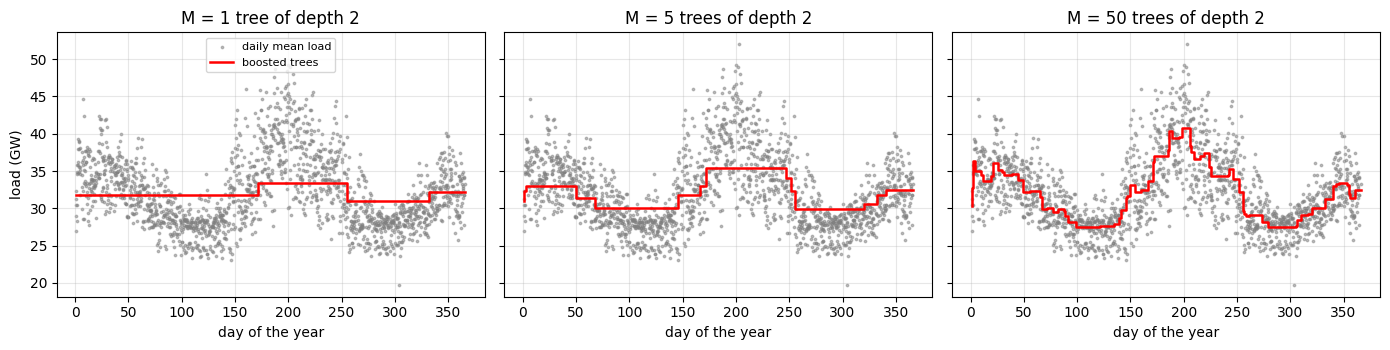

In [4]:
pjme_raw = pd.read_csv("data/PJME_hourly.csv", index_col="Datetime", parse_dates=True)
daily = pjme_raw["PJME_MW"].sort_index()["2010":"2014"].resample("D").mean()
x_demo = daily.index.dayofyear.to_numpy().reshape(-1, 1)      # XGBoost expects a 2-D feature array

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, M in zip(axes, [1, 5, 50]):
    demo = xgb.XGBRegressor(n_estimators=M, max_depth=2, learning_rate=0.3).fit(x_demo, daily)
    grid = np.arange(1, 367).reshape(-1, 1)
    ax.scatter(x_demo, daily / 1000, s=3, color="gray", alpha=0.5, label="daily mean load")
    ax.step(grid, demo.predict(grid) / 1000, where="mid", color="red", lw=1.8, label="boosted trees")
    ax.set(title=f"M = {M} tree{'s' if M > 1 else ''} of depth 2", xlabel="day of the year")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("load (GW)")
axes[0].legend(loc="upper center", fontsize=8)
plt.tight_layout(); plt.show()

- **One tree** of depth 2 has four leaves, so it predicts four levels. With $\eta = 0.3$, the steps are also only 30% of the way from the starting value (the mean) to the data.
- **Five trees** already give the shape of the year: a winter peak, two shoulders in spring and autumn, and the summer peak.
- **Fifty trees** follow the annual cycle closely, as a fine step function. The scatter around it is the day-to-day variation (weekends, weather), which the day of the year alone cannot explain.

The forecast is always a step function of the features. Between two observed feature values it is constant, and beyond the largest observed value it stays at the last step. We will come back to this when we look at the `year` feature.

---

# The PJM East hourly load

PJM Interconnection runs the electricity grid of all or part of 13 US states, from New Jersey to Illinois. The file `data/PJME_hourly.csv` holds the hourly load of its eastern region (PJM East) in megawatts (MW), from 2002 to August 2018.

In [5]:
print(pjme_raw.head(3), "\n")
idx = pjme_raw.index
print(f"rows: {len(pjme_raw)},  from {idx.min()} to {idx.max()}")
print(f"sorted by time: {idx.is_monotonic_increasing}")
print(f"duplicated time stamps: {idx.duplicated().sum()}:", list(idx[idx.duplicated()].date))
missing = pd.date_range(idx.min(), idx.max(), freq="h").difference(idx)
print(f"missing hours: {len(missing)}, e.g.", list(missing[:3]))

                     PJME_MW
Datetime                    
2002-12-31 01:00:00  26498.0
2002-12-31 02:00:00  25147.0
2002-12-31 03:00:00  24574.0 

rows: 145366,  from 2002-01-01 01:00:00 to 2018-08-03 00:00:00
sorted by time: False
duplicated time stamps: 4: [datetime.date(2014, 11, 2), datetime.date(2015, 11, 1), datetime.date(2016, 11, 6), datetime.date(2017, 11, 5)]
missing hours: 30, e.g. [Timestamp('2002-04-07 03:00:00'), Timestamp('2002-10-27 02:00:00'), Timestamp('2003-04-06 03:00:00')]


The file is not sorted, and it follows local clock time. When the clocks go back in November, one hour appears twice; when they go forward in spring, one hour is missing. A tree ensemble does not need a regular time grid, since each row is an independent example. We only sort the rows and average the duplicated hours.

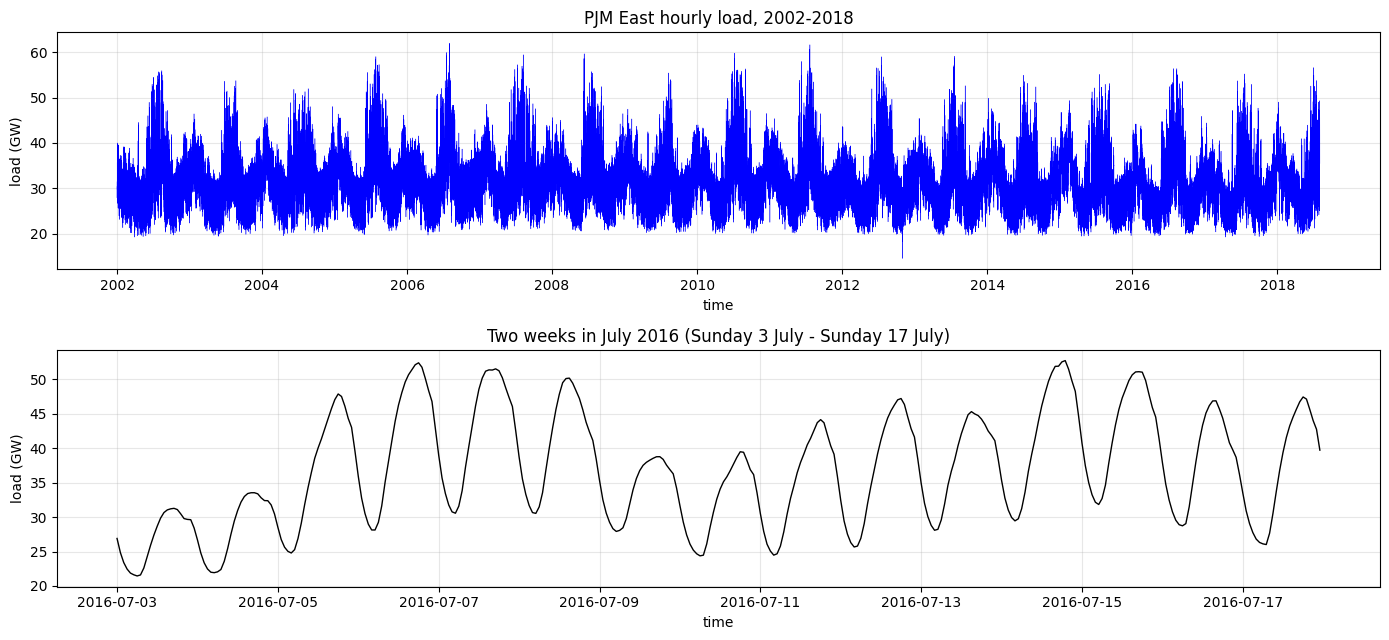

lowest loads:
Datetime
2012-10-30 04:00:00    14544.0
2012-10-30 03:00:00    14586.0
2012-10-30 05:00:00    14821.0
Name: PJME_MW, dtype: float64


In [6]:
pjme = pjme_raw["PJME_MW"].groupby(level=0).mean().sort_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 6.5))
axes[0].plot(pjme / 1000, color="blue", lw=0.3)
axes[0].set(title="PJM East hourly load, 2002-2018", xlabel="time", ylabel="load (GW)")
axes[0].grid(alpha=0.3)
run_sequence_plot(pjme["2016-07-03":"2016-07-17"] / 1000, ax=axes[1], ylabel="load (GW)", color="black",
                  title="Two weeks in July 2016 (Sunday 3 July - Sunday 17 July)")
plt.tight_layout(); plt.show()

print("lowest loads:")
print(pjme.nsmallest(3))

The plot shows three cycles at once:

- an **annual** cycle with two peaks, a high one in summer (air conditioning) and a lower one in winter (heating), with troughs in spring and autumn;
- a **weekly** cycle: the weekend load is lower than the weekday load, and so is the load on Monday 4 July, a holiday;
- a **daily** cycle: low at night, high in the afternoon and early evening.

There is no clear trend. The lowest loads in the whole series, about 15 GW, are from 30 October 2012, when Hurricane Sandy cut power to millions of customers. They are real, not errors, so we keep them.

---

# Train/test split

As in the earlier chapters, the test period must lie after the training period. Following the source tutorial, we hold out everything from 1 January 2015 on: three years and seven months of hourly data. The forecast is made at the end of 2014, for horizons of one hour up to 3.6 years.

training: 2002-01-01 01:00:00 to 2014-12-31 23:00:00  (113925 hours)
test:     2015-01-01 00:00:00 to 2018-08-03 00:00:00  (31437 hours)


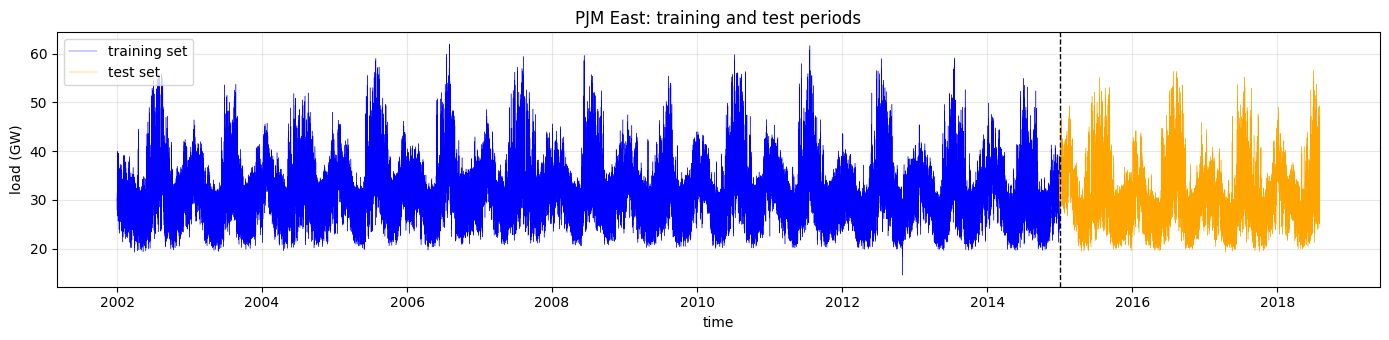

In [7]:
split_date = "2015-01-01"
y_train = pjme[pjme.index < split_date]
y_test = pjme[pjme.index >= split_date]
print(f"training: {y_train.index[0]} to {y_train.index[-1]}  ({len(y_train)} hours)")
print(f"test:     {y_test.index[0]} to {y_test.index[-1]}  ({len(y_test)} hours)")

_, ax = plt.subplots(figsize=(14, 3.5))
ax.plot(y_train / 1000, lw=0.3, color="blue", label="training set")
ax.plot(y_test / 1000, lw=0.3, color="orange", label="test set")
ax.axvline(pd.Timestamp(split_date), color="black", ls="--", lw=1)
ax.set(title="PJM East: training and test periods", xlabel="time", ylabel="load (GW)")
ax.grid(alpha=0.3); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

---

# Calendar features

The only information in the series itself is the time stamp and the load. `create_features` derives eight **calendar features** from the time stamp: hour, day of week, quarter, month, year, day of year, day of month and week of the year. All of them are known for any future time stamp, so the model can forecast as far ahead as we like, without any lagged values of the load.

In [8]:
X_train = create_features(y_train.index)
X_test = create_features(y_test.index)
print(X_train.iloc[[0, 1, 5000]])

                     hour  dayofweek  quarter  month  year  dayofyear  \
Datetime                                                                
2002-01-01 01:00:00     1          1        1      1  2002          1   
2002-01-01 02:00:00     2          1        1      1  2002          1   
2002-07-28 10:00:00    10          6        3      7  2002        209   

                     dayofmonth  weekofyear  
Datetime                                     
2002-01-01 01:00:00           1           1  
2002-01-01 02:00:00           1           1  
2002-07-28 10:00:00          28          30  


Box plots of the load by feature value show which features carry information, and in what shape.

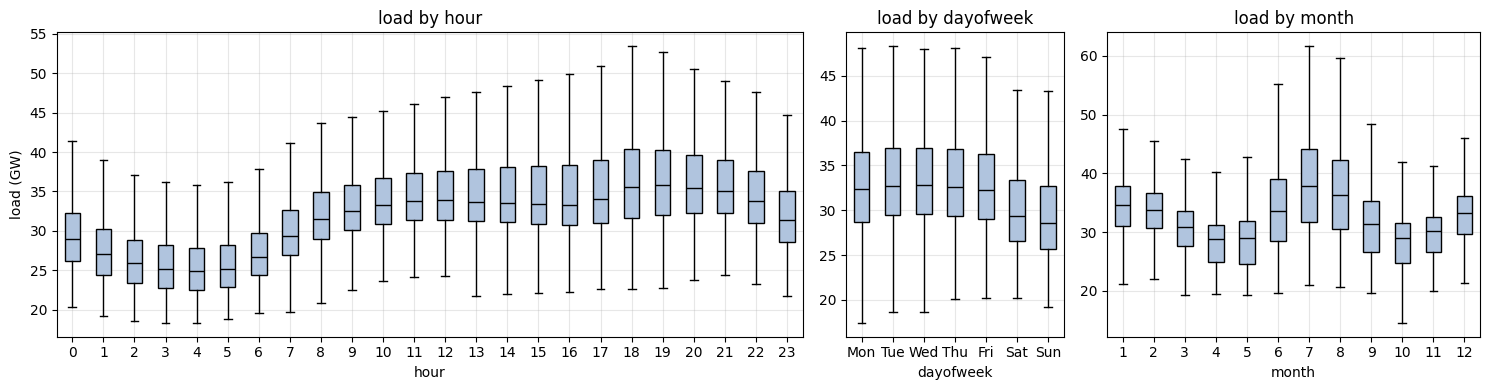

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [24, 7, 12]})
for ax, feature in zip(axes, ["hour", "dayofweek", "month"]):
    values = sorted(X_train[feature].unique())
    groups = [y_train[X_train[feature] == v] / 1000 for v in values]
    ax.boxplot(groups, tick_labels=values, showfliers=False, patch_artist=True,
               boxprops={"facecolor": "lightsteelblue"}, medianprops={"color": "black"})
    ax.set(title=f"load by {feature}", xlabel=feature)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("load (GW)")
axes[1].set_xticks(range(1, 8), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
plt.tight_layout(); plt.show()

- **Hour**: the median load is lowest at 3-5 a.m., rises steeply in the morning, and peaks at 6-8 p.m. (hours 18-20), about 11 GW higher. The spread is largest in the late afternoon, when air conditioning drives the summer peaks.
- **Day of week**: the five weekdays look alike; Saturday and Sunday are a few gigawatts lower.
- **Month**: July and August have the highest medians and by far the widest spread, January and February a smaller second peak, April, May, October and November are the quiet months.

None of these effects is linear in the feature. In a linear regression we would need dummy variables or Fourier terms (Chapters 7 and 13) to represent them; a tree finds the steps itself.

---

# Fitting XGBoost

## Early stopping on a validation year

The number of trees $M$ is the main control on overfitting. XGBoost can choose it by **early stopping**: after each new tree, it computes the error on a separate evaluation set, and stops when that error has not improved for `early_stopping_rounds` rounds.

The source tutorial passes the test set as the evaluation set. Then the test period chooses $M$, and the test error is no longer an honest estimate of the forecast error, the same mistake as selecting a model by its test RMSE. We cut a **validation year**, 2014, from the end of the training period instead: trees are fitted on 2002-2013, $M$ is chosen on 2014, and the test period stays untouched.

time required: 22 s
best number of trees: 1084,  validation RMSE 3483 MW


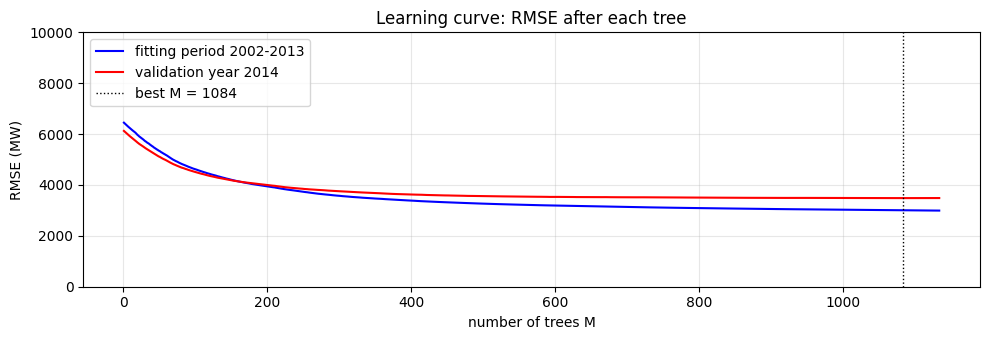

In [10]:
val_start = "2014-01-01"
in_fit = X_train.index < val_start

params = {"learning_rate": 0.01, "max_depth": 3}
start = time.perf_counter()
reg_es = xgb.XGBRegressor(n_estimators=5000, early_stopping_rounds=50, **params)
reg_es.fit(X_train[in_fit], y_train[in_fit],
           eval_set=[(X_train[in_fit], y_train[in_fit]), (X_train[~in_fit], y_train[~in_fit])], verbose=False)
print(f"time required: {time.perf_counter() - start:.0f} s")

n_trees = reg_es.best_iteration + 1
history = reg_es.evals_result()
rmse_fit, rmse_val = history["validation_0"]["rmse"], history["validation_1"]["rmse"]
print(f"best number of trees: {n_trees},  validation RMSE {rmse_val[n_trees - 1]:.0f} MW")

_, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(np.arange(1, len(rmse_fit) + 1), rmse_fit, color="blue", label="fitting period 2002-2013")
ax.plot(np.arange(1, len(rmse_val) + 1), rmse_val, color="red", label="validation year 2014")
ax.axvline(n_trees, color="black", ls=":", lw=1, label=f"best M = {n_trees}")
ax.set(title="Learning curve: RMSE after each tree", xlabel="number of trees M", ylabel="RMSE (MW)", ylim=(0, 10000))
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

With $\eta = 0.01$, every tree corrects only 1% of the remaining error, so the RMSE falls slowly over the first few hundred trees. The two curves cross at about 150 trees. After that, the fitting RMSE keeps falling, while the validation RMSE flattens out at about 3,500 MW: the extra trees learn details of 2002-2013 that carry over to 2014 less and less. The validation curve is almost flat from about 600 trees on, and early stopping halts when 50 more trees have brought no improvement. With depth-3 trees and a small learning rate, overfitting is slow, so the exact number of trees matters little here.

Having chosen $M$, we refit with that number of trees on the whole training period, 2002-2014, so that the most recent year also informs the forecast.

In [11]:
reg = xgb.XGBRegressor(n_estimators=n_trees, **params).fit(X_train, y_train)

## Feature importance

XGBoost reports three kinds of **feature importance**:

- **weight**: how many times the feature is used in a split, over all trees (this is what the source tutorial plots);
- **gain**: the average reduction of the loss per split on the feature;
- **total gain**: weight × gain, the total reduction of the loss due to the feature.

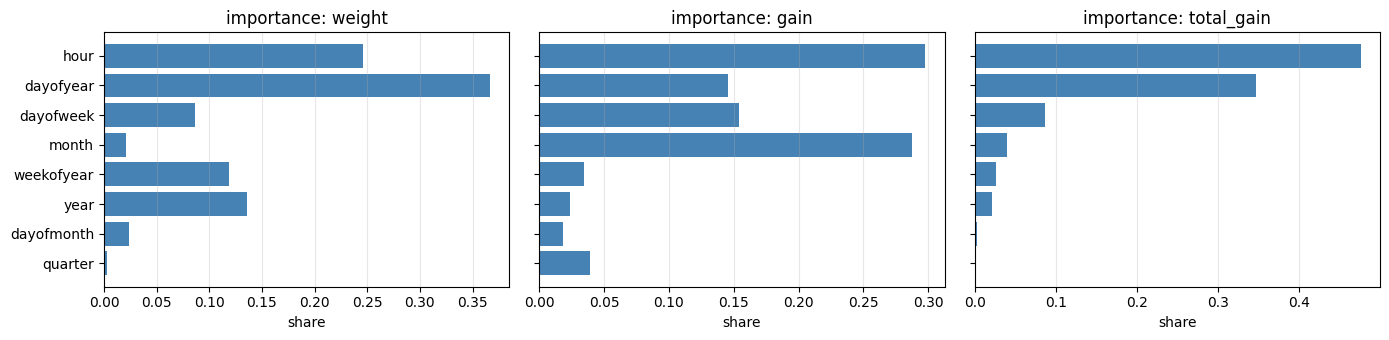

            weight   gain  total_gain
hour         0.246  0.298       0.476
dayofyear    0.366  0.146       0.347
dayofweek    0.087  0.154       0.087
month        0.021  0.287       0.040
weekofyear   0.118  0.035       0.027
year         0.135  0.024       0.021
dayofmonth   0.023  0.018       0.003
quarter      0.003  0.039       0.001


In [12]:
booster = reg.get_booster()
importance = pd.DataFrame({kind: pd.Series(booster.get_score(importance_type=kind))
                           for kind in ["weight", "gain", "total_gain"]})
importance = importance / importance.sum()                # shares, to compare the three columns
importance = importance.sort_values("total_gain")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, kind in zip(axes, importance.columns):
    ax.barh(importance.index, importance[kind], color="steelblue")
    ax.set(title=f"importance: {kind}", xlabel="share")
    ax.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()
print(importance.iloc[::-1].round(3))

The three measures rank the features differently, and the reason is instructive.

- By **weight**, `dayofyear` and `hour` lead. A feature with many distinct values offers many split points, and fine adjustments of the annual cycle take many small splits.
- By **gain**, `hour` and `month` lead: a split on the month separates summer from spring in one step, so each split on it removes a lot of error, but it is needed only a few times.
- By **total gain**, the best summary of what each feature contributes, `hour` dominates, followed by `dayofyear`, `dayofweek` and `month`. `quarter` and `dayofmonth` add almost nothing, since a quarter is a group of months and the day of the month carries no information of its own.

Importance tells us which features the trees use. It does not tell us the direction or the shape of the effect, and when two features carry the same information (`month`, `quarter`, `dayofyear`, `weekofyear`), the credit is split between them arbitrarily.

---

# Forecasting the test period

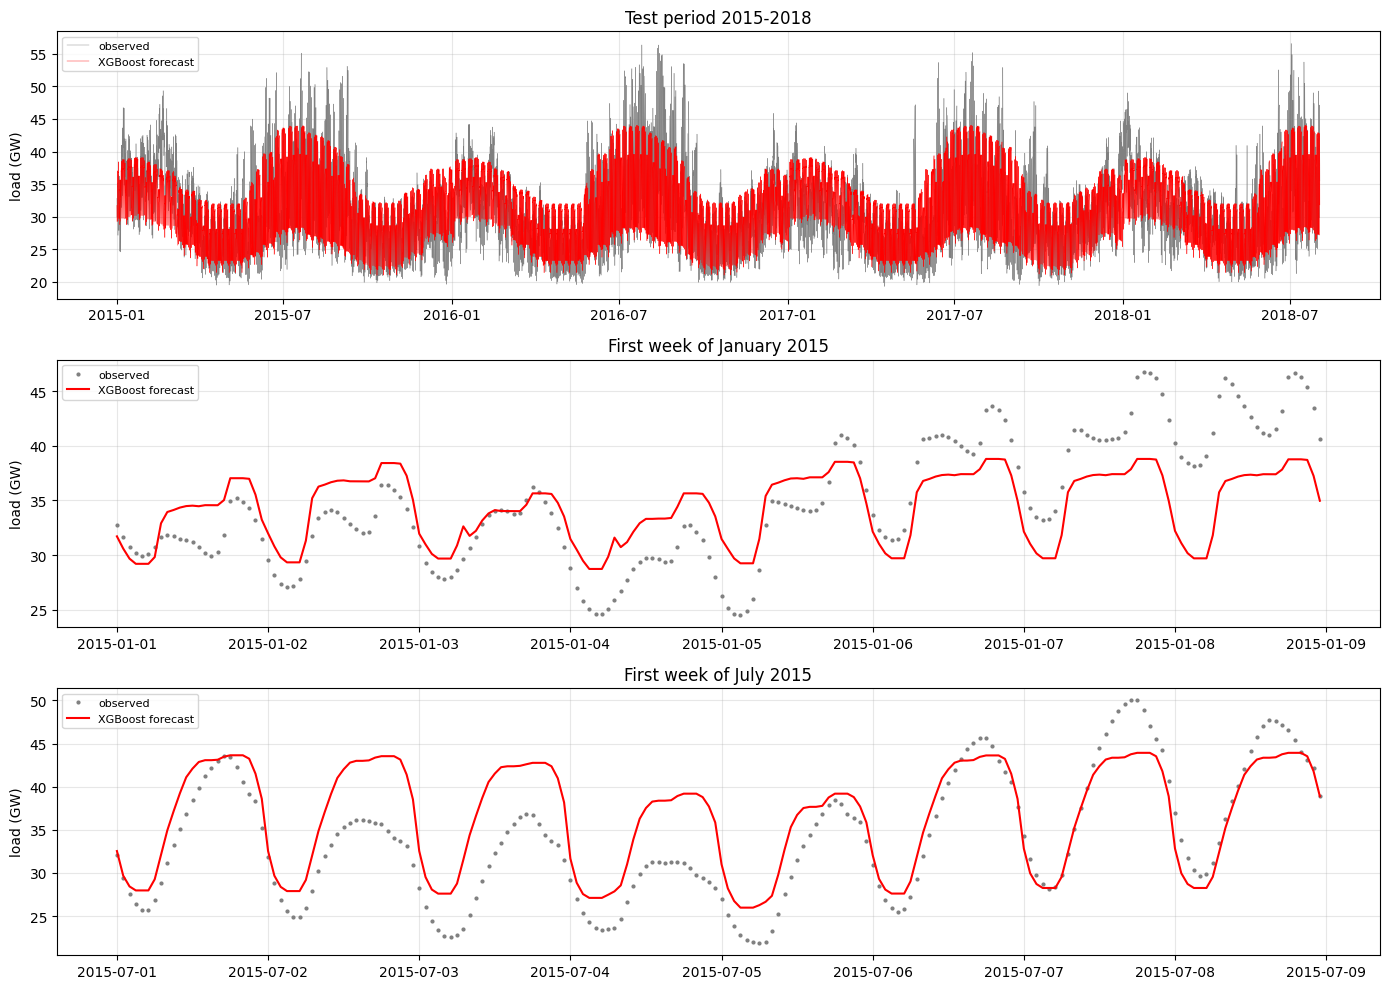

In [13]:
pred = pd.Series(reg.predict(X_test), index=y_test.index)

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
axes[0].plot(y_test / 1000, color="gray", lw=0.3, label="observed")
axes[0].plot(pred / 1000, color="red", lw=0.3, label="XGBoost forecast")
axes[0].set(title="Test period 2015-2018", ylabel="load (GW)")
for ax, (a, b, title) in zip(axes[1:], [("2015-01-01", "2015-01-08", "First week of January 2015"),
                                         ("2015-07-01", "2015-07-08", "First week of July 2015")]):
    ax.plot(y_test[a:b] / 1000, ".", color="gray", ms=4, label="observed")
    ax.plot(pred[a:b] / 1000, color="red", lw=1.5, label="XGBoost forecast")
    ax.set(title=title, ylabel="load (GW)")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

The forecast reproduces the shape of the year, the week and the day, but it is the same shape in every year: it is an average of what the training years did at that time of the year, week and day. It cannot know that the first week of January 2015 began with the New Year holiday and ended in a cold spell (the forecast is 5-8 GW too low on 6-8 January), or that 2-5 July 2015 were cool days around the 4 July holiday weekend.

How good is that? We compare the forecast with a simple benchmark that uses the same information: the **mean training load for each combination of month, day of the week and hour** ($12 \times 7 \times 24 = 2016$ averages, a lookup table). If XGBoost cannot beat that, the trees add nothing.

In [14]:
keys = lambda s: [s.index.month, s.index.dayofweek, s.index.hour]
profile = y_train.groupby(keys(y_train)).mean()
benchmark = profile.reindex(pd.MultiIndex.from_arrays(keys(y_test))).to_numpy()

table = pd.DataFrame({"month x weekday x hour means": accuracy(y_test, benchmark),
                      "XGBoost, calendar features": accuracy(y_test, pred)}).T
table.round(2)

,RMSE,MAE,MAPE (%)
month x weekday x hour means,3803.57,3016.57,9.71
"XGBoost, calendar features",3721.61,2879.89,9.07


XGBoost's RMSE is about 3,720 MW (an MSE of 13.8 million MW², which the source tutorial reports by mistake as the RMSE), its MAE about 2,880 MW and its MAPE about 9.1%. That matches the source closely. The lookup table of 2016 averages is only a little worse: about 2% higher RMSE and 0.6 percentage points higher MAPE. With calendar features alone, the trees learn a smoothed seasonal profile, and that is most of what there is to learn. The remaining error is mainly weather, which the calendar cannot predict.

## Trees cannot extrapolate

The feature `year` deserves a closer look. In the training data it runs from 2002 to 2014, in the test data from 2015 to 2018. A tree can only send a test value of 2017 to the leaf for "year > some split point within 2002-2014", so every test year is treated like the last training year. We check this by predicting the load at one fixed time (3 p.m., 15 July) and changing only the year.

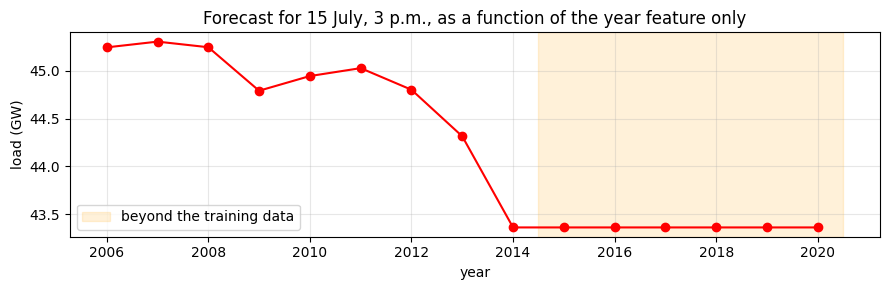

annual mean load (GW): {2002: 31.6, 2003: 31.7, 2004: 32.3, 2005: 33.3, 2006: 32.4, 2007: 33.6, 2008: 32.9, 2009: 31.9, 2010: 33.1, 2011: 32.4, 2012: 31.4, 2013: 31.7, 2014: 31.5, 2015: 31.7, 2016: 31.3, 2017: 30.7, 2018: 31.8}


In [15]:
probe = create_features(pd.DatetimeIndex(["2014-07-15 15:00"]))
years = np.arange(2006, 2021)
effect = []
for year in years:
    probe["year"] = year
    effect.append(reg.predict(probe)[0])

_, ax = plt.subplots(figsize=(9, 3))
ax.plot(years, np.array(effect) / 1000, "o-", color="red")
ax.axvspan(2014.5, 2020.5, color="orange", alpha=0.15, label="beyond the training data")
ax.set(title="Forecast for 15 July, 3 p.m., as a function of the year feature only", xlabel="year", ylabel="load (GW)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()
print("annual mean load (GW):", (pjme.groupby(pjme.index.year).mean() / 1000).round(1).to_dict())

From 2015 on, the forecast is flat: the `year` feature has no effect beyond the training range. A tree ensemble forecasts with the level of the last part of the training period, whatever trend there was before. For PJM East this does no harm, because the annual mean load has been roughly flat since 2002 (between about 30.7 and 33.6 GW). For a series with a trend, it would be a serious limitation. The usual remedies are to remove the trend first (by differencing or a regression, as in Chapter 13) and model the rest with trees, or to give the trees lagged values of the series, which carry the current level.

---

# Worst and best predicted days

To see where the model fails, we average the errors $e_t = y_t - \hat y_t$ over each day of the test period, and sort the days.

In [16]:
holidays = USFederalHolidayCalendar().holidays(start="2002-01-01", end="2018-12-31")
errors = pd.DataFrame({"load": y_test, "forecast": pred, "error": y_test - pred,
                       "abs_error": (y_test - pred).abs()})
by_day = errors.resample("D").mean()
by_day["weekday"] = by_day.index.day_name()
by_day["holiday"] = by_day.index.isin(holidays)

print("Most over-forecast days (most negative error):")
print(by_day.sort_values("error").head(10).round(0), "\n")
print("Worst days by absolute error:")
print(by_day.sort_values("abs_error", ascending=False).head(8).round(0), "\n")
print("Best days:")
print(by_day.sort_values("abs_error").head(5).round(0))

Most over-forecast days (most negative error):
               load  forecast   error  abs_error    weekday  holiday
Datetime                                                            
2016-07-04  28400.0   37062.0 -8662.0     8662.0     Monday     True
2017-02-24  26445.0   33677.0 -7232.0     7232.0     Friday    False
2015-12-25  24466.0   31666.0 -7200.0     7200.0     Friday     True
2016-06-09  27318.0   34306.0 -6988.0     6988.0   Thursday    False
2015-07-03  30025.0   36951.0 -6926.0     6926.0     Friday     True
2017-02-20  27071.0   33952.0 -6882.0     6882.0     Monday     True
2017-09-04  26552.0   33401.0 -6848.0     6848.0     Monday     True
2017-06-08  26944.0   33730.0 -6787.0     6787.0   Thursday    False
2017-09-02  24201.0   30950.0 -6748.0     6748.0   Saturday    False
2017-02-08  28524.0   35260.0 -6737.0     6737.0  Wednesday    False 

Worst days by absolute error:
               load  forecast    error  abs_error   weekday  holiday
Datetime                

- **Over-forecast days are mostly holidays**: 4 July 2016, Christmas 2015, Friday 3 July 2015 (the observed Independence Day holiday that year), Presidents' Day 2017, Labor Day 2017. On a holiday, the load looks like a Sunday's, but the model only knows that it is a weekday. The other days in the list are mild weekdays in February and June, and the Saturday of the Labor Day weekend 2017.
- **The largest absolute errors are under-forecasts**, in heat waves (12-14 August and 9-10 September 2016) and cold snaps (20-21 February 2015, 6 January 2018): the load was 10-13 GW above the forecast. Those are weather, and no calendar feature can anticipate them.
- **The best days** are in May and October, mild months with little heating or cooling and no holidays.

The holidays at least are known in advance. We plot the worst day and one holiday, then add a holiday feature.

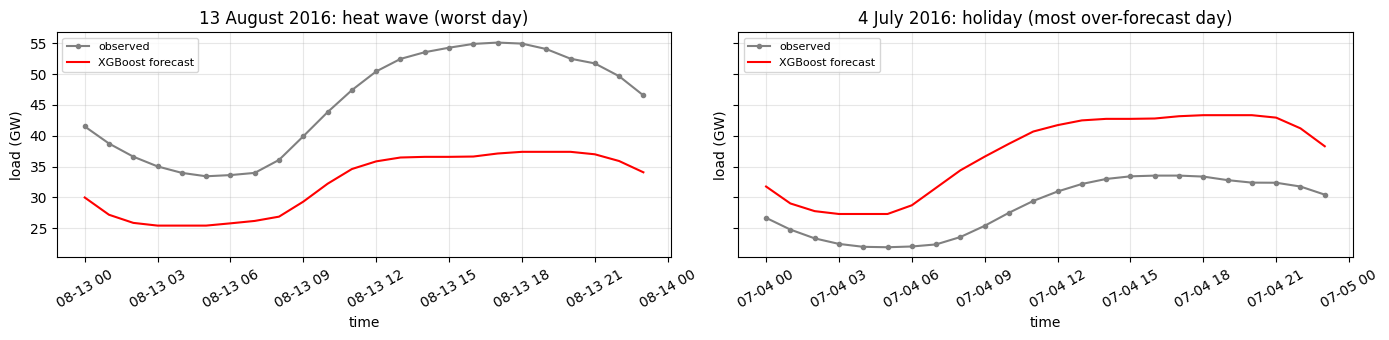

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for ax, (day, title) in zip(axes, [("2016-08-13", "13 August 2016: heat wave (worst day)"),
                                   ("2016-07-04", "4 July 2016: holiday (most over-forecast day)")]):
    ax.plot(y_test[day] / 1000, "o-", color="gray", ms=3, label="observed")
    ax.plot(pred[day] / 1000, color="red", lw=1.5, label="XGBoost forecast")
    ax.set(title=title, xlabel="time", ylabel="load (GW)")
    ax.tick_params(axis="x", labelrotation=30)
    ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

On 13 August 2016, the shape of the day is right but the level is 13 GW too low all day. On 4 July 2016, the forecast is a normal summer Monday, while the observed load stays 7-10 GW below it from the morning on.

---

# Adding a holiday feature

`USFederalHolidayCalendar` lists the ten US federal holidays, moved to the nearest weekday when they fall on a weekend (as 3 July 2015 was). We add a 0/1 feature `holiday`, repeat the early stopping on the validation year, refit on 2002-2014, and evaluate on the whole test period and on the holidays alone.

In [18]:
X_train_h = create_features(y_train.index, holidays)
X_test_h = create_features(y_test.index, holidays)

reg_es_h = xgb.XGBRegressor(n_estimators=5000, early_stopping_rounds=50, **params)
reg_es_h.fit(X_train_h[in_fit], y_train[in_fit], eval_set=[(X_train_h[~in_fit], y_train[~in_fit])], verbose=False)
n_trees_h = reg_es_h.best_iteration + 1
reg_h = xgb.XGBRegressor(n_estimators=n_trees_h, **params).fit(X_train_h, y_train)
pred_h = pd.Series(reg_h.predict(X_test_h), index=y_test.index)
print(f"best number of trees with the holiday feature: {n_trees_h}")

is_holiday = X_test_h["holiday"] == 1
rows = {}
for name, p in [("month x weekday x hour means", benchmark), ("XGBoost, calendar", pred.to_numpy()),
                ("XGBoost, calendar + holiday", pred_h.to_numpy())]:
    rows[name] = {**accuracy(y_test, p),
                  "MAPE holidays (%)": mape(y_test[is_holiday], p[is_holiday]),
                  "MAPE other days (%)": mape(y_test[~is_holiday], p[~is_holiday])}
pd.DataFrame(rows).T.round(2)

best number of trees with the holiday feature: 1228


,RMSE,MAE,MAPE (%),MAPE holidays (%),MAPE other days (%)
month x weekday x hour means,3803.57,3016.57,9.71,14.20,9.58
"XGBoost, calendar",3721.61,2879.89,9.07,13.51,8.95
"XGBoost, calendar + holiday",3717.20,2873.45,9.03,11.46,8.97


The holiday feature lowers the MAPE on the holidays from about 13.5% to 11.5%, and leaves the other days unchanged. Over the whole test period, the gain is negligible, because holidays are only about 3% of the hours. The holidays are still forecast worse than the other days.

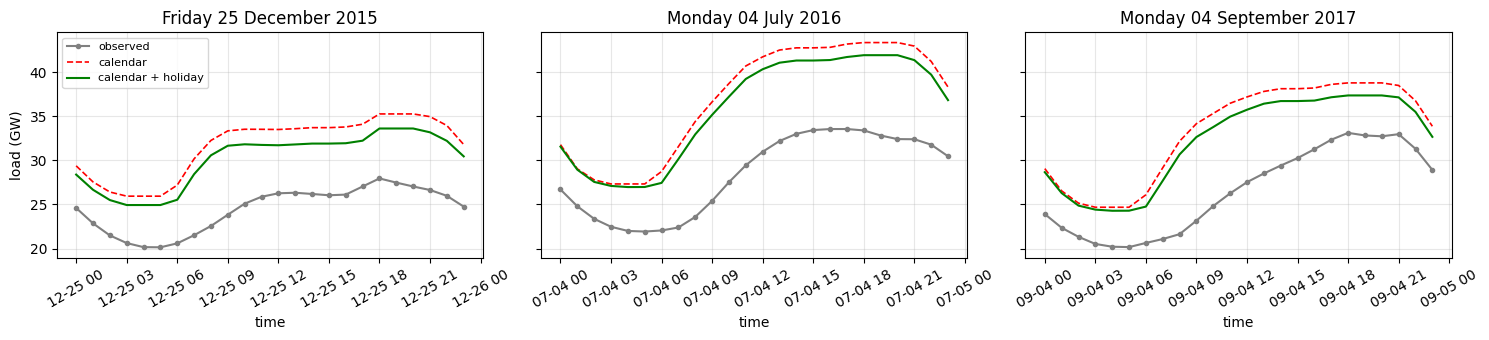

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, day in zip(axes, ["2015-12-25", "2016-07-04", "2017-09-04"]):
    ax.plot(y_test[day] / 1000, "o-", color="gray", ms=3, label="observed")
    ax.plot(pred[day] / 1000, color="red", lw=1.2, ls="--", label="calendar")
    ax.plot(pred_h[day] / 1000, color="green", lw=1.5, label="calendar + holiday")
    ax.set(title=pd.Timestamp(day).strftime("%A %d %B %Y"), xlabel="time")
    ax.tick_params(axis="x", labelrotation=30)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("load (GW)"); axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

On these three holidays, the holiday feature lowers the forecast by only 1-2 GW, while the observed load is 7-10 GW below the weekday forecast. To see why, we look at the mean percentage error of the two models on each holiday of the test period.

In [20]:
names = USFederalHolidayCalendar().holidays(start="2015-01-01", end="2018-08-02", return_name=True)
day_load = y_test.resample("D").mean()
pct_error = lambda p: 100 * (day_load - p.resample("D").mean()) / day_load
per_holiday = pd.DataFrame({"holiday": names.to_numpy(),
                            "calendar": pct_error(pred).reindex(names.index).to_numpy(),
                            "calendar + holiday": pct_error(pred_h).reindex(names.index).to_numpy()})
per_holiday.groupby("holiday").mean().sort_values("calendar").round(1)

,calendar,calendar + holiday
holiday,,
Memorial Day,-14.5,-8.8
Independence Day,-14.1,-10.5
Christmas Day,-14.1,-7.6
Thanksgiving Day,-13.0,-5.3
Labor Day,-12.0,-8.0
Veterans Day,-4.5,-2.0
New Year's Day,-2.9,-2.4
"Birthday of Martin Luther King, Jr.",0.1,1.9
Washington's Birthday,0.4,2.9


The federal holidays are not alike. On Memorial Day, Independence Day, Labor Day, Thanksgiving and Christmas, most businesses close: the calendar-only model over-forecasts them by 12-15%. On Martin Luther King Day, Washington's Birthday (Presidents' Day) and Columbus Day, most businesses stay open and the load is that of an ordinary weekday: the calendar-only model has practically no error there.

A single 0/1 feature must serve both groups, so the trees learn a holiday effect in between. It removes only part of the over-forecast on the major holidays, and creates an under-forecast of 2-4% on the minor ones. The remedy is again feature engineering, not tuning: separate indicators for major and minor holidays, and for the days around them (the Friday after Thanksgiving, the days between Christmas and New Year), which are not federal holidays at all.

---

# Summary

**Gradient-boosted trees**: $\ \hat y_i = \hat y_i^{(0)} + \eta \sum_{m=1}^{M} f_m(\mathbf{x}_i)$, where each $f_m$ is a shallow regression tree fitted to the residuals (in general, the negative gradient of the loss) of the trees before it.

- XGBoost minimizes the loss plus a complexity penalty $\Omega(f) = \gamma T + \tfrac12 \lambda \sum_j w_j^2$ on each tree. The main hyperparameters are the number of trees $M$, the learning rate $\eta$, and the tree depth.
- To forecast with it, turn the series into a table: one row per time stamp, the series as the target, and features known in advance, such as **calendar features**.
- Split in time order: training, then **validation** (to choose $M$ by early stopping, or other hyperparameters), then test. Never use the test period for early stopping.
- Trees capture non-linear effects and interactions without dummies or Fourier terms, but their forecasts are step functions that **cannot extrapolate**: beyond the training range of a feature, the forecast stays at the last step. Remove trends first, or give the model lagged values.
- Feature importances (weight, gain, total gain) show which features the trees use, not the shape of the effects; correlated features share the credit.